# Дополнительное задание. TensorFlow: 5-fold CV, Grid Search и TensorBoard

**Цель:** воспроизводимо сравнить девять конфигураций нейросети для четырёхклассовой
классификации и проверить результат относительно фиксированной baseline-модели.
Используется Mobile Price Classification из лабораторной работы 2.

План: первичный анализ → baseline → стратифицированная 5-fold CV → полный перебор
3 архитектур × 3 learning rate → TensorBoard и статические кривые → сравнение
качества, loss, времени и устойчивости → refit победителя и тестовая оценка.

Все конфигурации обучаются ровно **60 эпох**, batch size **64**. Валидационные метрики
записываются, но EarlyStopping, подбор эпох и восстановление весов по проверочному
фолду не применяются. Оценка каждого фолда соответствует последней эпохе.
Выбор конфигурации использует только CV; после выбора GridSearchCV выполняет один
refit на всей обучающей части. Baseline — LogisticRegression с фиксированными параметрами.

Сохраняется внешнее разбиение 80/20 с seed 42 из основной работы. Его тест уже
анализировался в предыдущей работе: это повторное учебное сравнение на известном
наборе, а не новая внешняя проверка. В дополнительной работе тест не участвует
в поиске параметров, построении фолдов и остановке обучения.

Текстовые выводы сформированы из реальных вычислений. Команда
`python generate_additional_notebook.py` повторяет расчёт и обновляет Markdown.

In [1]:
RANDOM_STATE = 42
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
import random
import warnings
warnings.filterwarnings("ignore")
import gc
import hashlib
import json
import platform
import shutil
import tempfile
import time
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import sklearn
import kagglehub
import joblib
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.metrics import (accuracy_score, log_loss, precision_score, recall_score,
                            f1_score, roc_auc_score, roc_curve, auc,
                            confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.validation import check_is_fitted
from threadpoolctl import threadpool_limits

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 20)
EPOCHS, BATCH_SIZE = 60, 64
CLASSES = np.array([0, 1, 2, 3])
ARTIFACTS = Path("additional") / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%fZ")
TB_WORKDIR = Path.cwd()
if os.name == "nt" and not str(TB_WORKDIR).isascii():
    TB_WORKDIR = Path(tempfile.mkdtemp(prefix="lab2_additional_tb_"))
    if not str(TB_WORKDIR).isascii():
        raise RuntimeError("TEMP должен иметь ASCII-путь для файлового backend TensorFlow.")
TB_ROOT = TB_WORKDIR / "logs" / "additional" / RUN_ID
ANALYSIS, FIT_RECORDS, HISTORIES, OOF_PREDICTIONS = {}, [], {}, []
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "TensorFlow": tf.__version__, "Keras": tf.keras.__version__}
display(pd.Series(versions, name="Версия").to_frame())

def show(name):
    plt.tight_layout()
    plt.savefig(ARTIFACTS / f"{name}.png", bbox_inches="tight")
    plt.show()

def dump_json(path, data):
    Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=2,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x))+"\n", encoding="utf-8")

def metric_row(truth, pred, proba):
    assert proba.shape == (len(truth), 4) and np.isfinite(proba).all()
    assert np.all(proba >= 0) and np.allclose(proba.sum(axis=1), 1, atol=1e-5)
    return {"accuracy": accuracy_score(truth, pred), "loss": log_loss(truth, proba, labels=CLASSES),
        "precision_macro": precision_score(truth, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(truth, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(truth, pred, average="macro", zero_division=0),
        "roc_auc_ovr_macro": roc_auc_score(label_binarize(truth, classes=CLASSES), proba,
                                          multi_class="ovr", average="macro")}

ANALYSIS["setup"] = (
    f"Среда: Python {versions['Python']}, TensorFlow {versions['TensorFlow']}, "
    f"Keras {versions['Keras']}, scikit-learn {versions['scikit-learn']}. "
    f"Базовый seed={RANDOM_STATE}, бюджет={EPOCHS} эпох, batch_size={BATCH_SIZE}. "
    "Для одинакового фолда все конфигурации получают одинаковый seed, для финального "
    "refit — 42. Включены детерминированные операции и один вычислительный поток. "
    "Результаты воспроизводимы в зафиксированной среде; между платформами побитовая "
    "идентичность вычислений не гарантируется.")

,Версия
Python,3.13.2
NumPy,2.2.4
pandas,3.0.3
scikit-learn,1.9.0
TensorFlow,2.21.0
Keras,3.15.1


### Интерпретация результатов

Среда: Python 3.13.2, TensorFlow 2.21.0, Keras 3.15.1, scikit-learn 1.9.0. Базовый seed=42, бюджет=60 эпох, batch_size=64. Для одинакового фолда все конфигурации получают одинаковый seed, для финального refit — 42. Включены детерминированные операции и один вычислительный поток. Результаты воспроизводимы в зафиксированной среде; между платформами побитовая идентичность вычислений не гарантируется.

## 1. Загрузка, качество данных и баланс классов

In [2]:
csv_path = Path("data") / "raw" / "train.csv"
if not csv_path.is_file():
    csv_path = Path(kagglehub.dataset_download("iabhishekofficial/mobile-price-classification")) / "train.csv"
df = pd.read_csv(csv_path)
FEATURES = ["battery_power", "blue", "clock_speed", "dual_sim", "fc", "four_g",
    "int_memory", "m_dep", "mobile_wt", "n_cores", "pc", "px_height", "px_width",
    "ram", "sc_h", "sc_w", "talk_time", "three_g", "touch_screen", "wifi"]
assert df.shape == (2000, 21) and set(df.columns) == set(FEATURES+["price_range"])
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)
assert not np.isinf(df.to_numpy()).any()
assert df.price_range.notna().all() and set(df.price_range) == set(CLASSES)
dataset_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
display(df.head())
df.info()
display(df.describe().T)
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "NaN": df.isnull().sum()})
duplicates = int(df.duplicated().sum())
display(quality)
print("Полных дубликатов:", duplicates)
assert duplicates == 0, "Перед разбиением требуется обработать изменившийся набор дубликатов."
ANALYSIS["data"] = (
    f"Загружено {len(df)} строк и {len(FEATURES)} входных признаков. "
    f"Пропусков во всех 21 столбце: {int(df.isnull().sum().sum())}; дубликатов: {duplicates}. "
    f"Типов float: {sum(pd.api.types.is_float_dtype(t) for t in df.dtypes)}, "
    f"целочисленных столбцов: {sum(pd.api.types.is_integer_dtype(t) for t in df.dtypes)}. "
    "Все входы числовые; бинарные признаки уже представлены кодами 0/1, "
    "OneHotEncoder и кодирование строковых категорий не требуются. Медианный импутер "
    "оставлен как защита, но искусственно создавать пропуски не нужно. "
    f"SHA-256: `{dataset_sha256}`.")

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


,dtype,NaN
battery_power,int64,0
blue,int64,0
clock_speed,float64,0
dual_sim,int64,0
fc,int64,0
four_g,int64,0
int_memory,int64,0
m_dep,float64,0
mobile_wt,int64,0
n_cores,int64,0


Полных дубликатов: 0


### Интерпретация результатов

Загружено 2000 строк и 20 входных признаков. Пропусков во всех 21 столбце: 0; дубликатов: 0. Типов float: 2, целочисленных столбцов: 19. Все входы числовые; бинарные признаки уже представлены кодами 0/1, OneHotEncoder и кодирование строковых категорий не требуются. Медианный импутер оставлен как защита, но искусственно создавать пропуски не нужно. SHA-256: `f9e8cd3154b8684a1be0ff401b1fba7750710af6bd076a399c6ce7ceb979c624`.

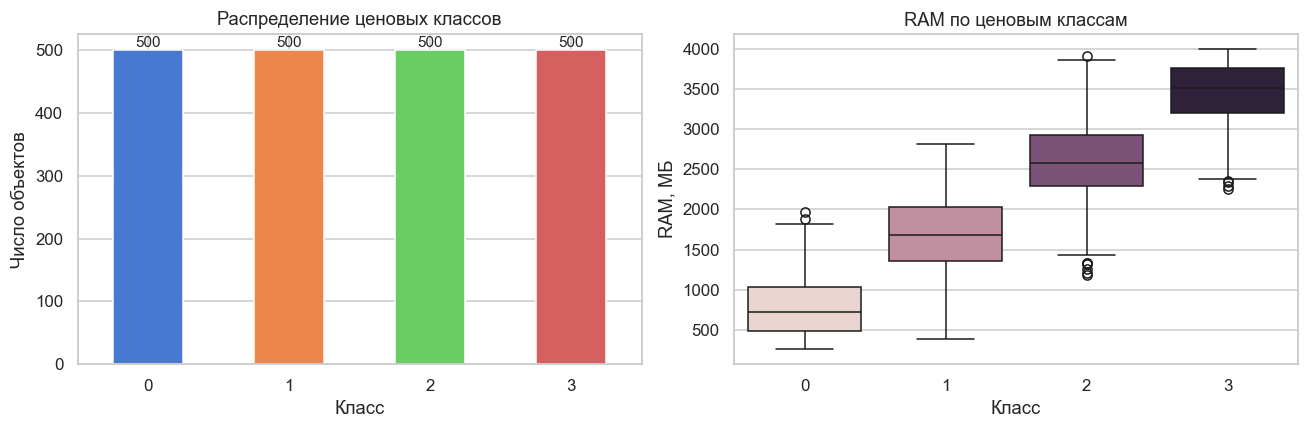

In [3]:
counts = df.price_range.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=axes[0], rot=0, color=sns.color_palette("muted", 4))
axes[0].set(title="Распределение ценовых классов", xlabel="Класс", ylabel="Число объектов")
for i, count in enumerate(counts):
    axes[0].text(i, count+5, str(count), ha="center")
sns.boxplot(data=df, x="price_range", y="ram", hue="price_range", legend=False, ax=axes[1])
axes[1].set(title="RAM по ценовым классам", xlabel="Класс", ylabel="RAM, МБ")
show("data_overview")
ram_corr = float(df.corr().loc["ram", "price_range"])
ANALYSIS["eda"] = (
    f"Численности классов 0–3 равны {counts.tolist()}, "
    f"доля каждого класса {counts.iloc[0]/len(df):.2%}. "
    f"Точность константного классификатора составляет {counts.max()/len(df):.4f}. "
    "Весовые поправки классов и ресемплинг не требуются. "
    f"Корреляция Пирсона RAM с номером ценового сегмента r={ram_corr:.4f}; "
    "она описывает порядковую ассоциацию и не доказывает причинность. "
    f"RAM меняется от {df.ram.min()} до {df.ram.max()}, тогда как бинарные признаки "
    "лежат в {0,1}: стандартизация устраняет несопоставимость численных масштабов. "
    "Все 20 признаков сохранены; EDA не используется для отбора входов или изменения сетки.")

### Интерпретация результатов

Численности классов 0–3 равны [500, 500, 500, 500], доля каждого класса 25.00%. Точность константного классификатора составляет 0.2500. Весовые поправки классов и ресемплинг не требуются. Корреляция Пирсона RAM с номером ценового сегмента r=0.9170; она описывает порядковую ассоциацию и не доказывает причинность. RAM меняется от 256 до 3998, тогда как бинарные признаки лежат в {0,1}: стандартизация устраняет несопоставимость численных масштабов. Все 20 признаков сохранены; EDA не используется для отбора входов или изменения сетки.

In [4]:
X, y = df[FEATURES], df.price_range.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.DataFrame({"train": y_train.value_counts().sort_index(),
                      "test": y_test.value_counts().sort_index()}))
ANALYSIS["split"] = (
    f"Внешний train содержит {len(X_train)} объектов, test — {len(X_test)}. "
    f"По классам в train: {y_train.value_counts().sort_index().tolist()}, "
    f"в test: {y_test.value_counts().sort_index().tolist()}. "
    "Сначала выполнено разбиение сырых данных, затем каждый обучающий процесс "
    "самостоятельно оценивает медианы, средние и стандартные отклонения. "
    "Ни скейлер, ни импутер не обучаются на всей таблице до CV. Внешнее разбиение "
    "совпадает с основной лабораторной; его результаты уже были известны ранее. "
    "В текущем поиске доступ к тесту не используется для выбора гиперпараметров.")

,train,test
price_range,,
0,400,100
1,400,100
2,400,100
3,400,100


### Интерпретация результатов

Внешний train содержит 1600 объектов, test — 400. По классам в train: [400, 400, 400, 400], в test: [100, 100, 100, 100]. Сначала выполнено разбиение сырых данных, затем каждый обучающий процесс самостоятельно оценивает медианы, средние и стандартные отклонения. Ни скейлер, ни импутер не обучаются на всей таблице до CV. Внешнее разбиение совпадает с основной лабораторной; его результаты уже были известны ранее. В текущем поиске доступ к тесту не используется для выбора гиперпараметров.

## 2. Baseline: логистическая регрессия

In [5]:
baseline_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE))])
baseline_start = time.perf_counter()
baseline_model.fit(X_train, y_train)
baseline_seconds = time.perf_counter()-baseline_start
baseline_proba = baseline_model.predict_proba(X_test)
baseline_pred = baseline_model.predict(X_test)
baseline_metrics = metric_row(y_test, baseline_pred, baseline_proba)
display(pd.DataFrame([baseline_metrics], index=["LogisticRegression"]).round(5))
joblib.dump(baseline_model, ARTIFACTS / "baseline_logistic.joblib")
ANALYSIS["baseline"] = (
    f"Фиксированная LogisticRegression: Accuracy={baseline_metrics['accuracy']:.4f}, "
    f"loss={baseline_metrics['loss']:.4f}, F1-macro={baseline_metrics['f1_macro']:.4f}, "
    f"ROC-AUC={baseline_metrics['roc_auc_ovr_macro']:.4f}; обучение заняло {baseline_seconds:.3f} с. "
    "Модель задаёт линейные границы в стандартизованном пространстве и служит "
    "практической точкой отсчёта для более гибкой MLP. C=1 и max_iter=2000 "
    "заданы заранее и не подбирались по тесту. Для нейросети требуется показать "
    "фактический эффект настройки; превосходство над линейным baseline не предполагается.")

,accuracy,loss,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro
LogisticRegression,0.965,0.18915,0.96504,0.965,0.96499,0.99867


### Интерпретация результатов

Фиксированная LogisticRegression: Accuracy=0.9650, loss=0.1892, F1-macro=0.9650, ROC-AUC=0.9987; обучение заняло 0.048 с. Модель задаёт линейные границы в стандартизованном пространстве и служит практической точкой отсчёта для более гибкой MLP. C=1 и max_iter=2000 заданы заранее и не подбирались по тесту. Для нейросети требуется показать фактический эффект настройки; превосходство над линейным baseline не предполагается.

## 3. Пять стратифицированных фолдов

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_SPLITS = list(cv.split(X_train, y_train))
FOLD_MONITORS, split_manifest, fold_rows = {}, [], []
for fold, (fit_pos, val_pos) in enumerate(CV_SPLITS, start=1):
    fit_index = X_train.iloc[fit_pos].index
    val_index = X_train.iloc[val_pos].index
    assert set(fit_index).isdisjoint(val_index)
    assert set(fit_index).isdisjoint(X_test.index)
    assert set(val_index).isdisjoint(X_test.index)
    # Registry identifies a fold from its training indices. Validation rows are used
    # only by Keras' validation pass for monitoring; no callback changes the weights.
    FOLD_MONITORS[frozenset(fit_index)] = (fold, X_train.iloc[val_pos], y_train.iloc[val_pos])
    split_manifest.append({"fold": fold, "train_indices": fit_index.tolist(),
        "validation_indices": val_index.tolist()})
    fold_rows.append({"fold": fold, "train": len(fit_pos), "validation": len(val_pos),
        **{f"validation_class_{c}": int((y_train.iloc[val_pos] == c).sum()) for c in CLASSES}})
display(pd.DataFrame(fold_rows).set_index("fold"))
dump_json(ARTIFACTS / "split_manifest.json", {"random_state": RANDOM_STATE,
    "outer_train_indices": X_train.index.tolist(), "outer_test_indices": X_test.index.tolist(),
    "folds": split_manifest})
ANALYSIS["cv"] = (
    f"Организованы {len(CV_SPLITS)} общих фолдов: каждый содержит 1280 train-объектов "
    "и 320 validation-объектов, по 80 наблюдений каждого проверочного класса. "
    "Для каждой конфигурации объект внешнего train ровно один раз попадает в validation. "
    "Одинаковые фолды и seed по номеру фолда делают сравнение конфигураций парным. "
    "Проверены непересечение train/validation и отсутствие всех 400 test-объектов в CV. "
    "Реестр FOLD_MONITORS передаёт проверочные данные только для отображения кривых; "
    "обучение длится фиксированные 60 эпох, градиенты по validation не вычисляются.")

,train,validation,validation_class_0,validation_class_1,validation_class_2,validation_class_3
fold,,,,,,
1,1280,320,80,80,80,80
2,1280,320,80,80,80,80
3,1280,320,80,80,80,80
4,1280,320,80,80,80,80
5,1280,320,80,80,80,80


### Интерпретация результатов

Организованы 5 общих фолдов: каждый содержит 1280 train-объектов и 320 validation-объектов, по 80 наблюдений каждого проверочного класса. Для каждой конфигурации объект внешнего train ровно один раз попадает в validation. Одинаковые фолды и seed по номеру фолда делают сравнение конфигураций парным. Проверены непересечение train/validation и отсутствие всех 400 test-объектов в CV. Реестр FOLD_MONITORS передаёт проверочные данные только для отображения кривых; обучение длится фиксированные 60 эпох, градиенты по validation не вычисляются.

## 4. TensorFlow-модель и полный Grid Search

In [7]:
ARCHITECTURES = {
    "shallow": {"units": [32], "regularized": False},
    "deep": {"units": [128, 64, 32], "regularized": False},
    "regularized": {"units": [128, 64, 32], "regularized": True}}
LEARNING_RATES = [0.0001, 0.001, 0.01]

def config_id(architecture, learning_rate):
    return f"{architecture}_lr_{learning_rate:g}"

def make_dataset(features, labels, training=False, seed=RANDOM_STATE):
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(features, dtype="float32"),
                                           np.asarray(labels, dtype="int32")))
    if training:
        ds = ds.shuffle(len(labels), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    options.experimental_deterministic = True
    return ds.batch(BATCH_SIZE).with_options(options).prefetch(1)

def build_network(architecture, learning_rate, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    spec = ARCHITECTURES[architecture]
    layers = [tf.keras.layers.Input(shape=(len(FEATURES),))]
    for units in spec["units"]:
        layers.append(tf.keras.layers.Dense(units, activation="relu"))
        if spec["regularized"]:
            layers.extend([tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3)])
    layers.append(tf.keras.layers.Dense(4, activation="softmax"))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

class TensorFlowClassifier(ClassifierMixin, BaseEstimator):
    """Cloneable sklearn estimator; all preprocessing is fitted inside fit()."""
    def __init__(self, architecture="shallow", learning_rate=0.001, epochs=EPOCHS,
                 random_state=RANDOM_STATE):
        self.architecture = architecture
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        assert np.array_equal(self.classes_, CLASSES)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = len(self.feature_names_in_)
        monitor = FOLD_MONITORS.get(frozenset(X.index))
        fold = monitor[0] if monitor else 0
        if monitor is None:
            assert set(X.index) == set(X_train.index), "Unknown training partition"
        seed = self.random_state + fold
        self.preprocessor_ = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                       ("scaler", StandardScaler())])
        fit_features = self.preprocessor_.fit_transform(X).astype("float32")
        validation_data = None
        if monitor is not None:
            _, val_X, val_y = monitor
            validation_data = make_dataset(self.preprocessor_.transform(val_X), val_y)
        self.model_ = build_network(self.architecture, self.learning_rate, seed)
        cfg = config_id(self.architecture, self.learning_rate)
        run = f"fold_{fold}" if fold else "refit"
        log_dir = TB_ROOT / cfg / run
        callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir.as_posix(), histogram_freq=1)
        start = time.perf_counter()
        history = self.model_.fit(make_dataset(fit_features, y, training=True, seed=seed),
            validation_data=validation_data, epochs=self.epochs, callbacks=[callback], verbose=0)
        seconds = time.perf_counter()-start
        self.history_ = history.history
        self.training_seconds_ = seconds
        archive = ARTIFACTS / "tensorboard" / cfg / run
        shutil.copytree(log_dir, archive, dirs_exist_ok=True)
        HISTORIES[f"{cfg}/{run}"] = history.history
        pd.DataFrame(history.history).rename_axis("epoch_zero_based").to_csv(
            ARTIFACTS / f"history_{cfg}_{run}.csv")
        record = {"config": cfg, "architecture": self.architecture, "learning_rate": self.learning_rate,
            "fold": fold, "seed": seed, "epochs": self.epochs, "n_train": len(X),
            "training_seconds": seconds, "log_path": archive.as_posix(),
            "train_loss_last": history.history["loss"][-1],
            "train_accuracy_last": history.history["accuracy"][-1],
            "preprocessor_mean": self.preprocessor_["scaler"].mean_.tolist(),
            "preprocessor_scale": self.preprocessor_["scaler"].scale_.tolist()}
        if monitor is not None:
            proba = self.predict_proba(val_X)
            pred = proba.argmax(axis=1)
            record.update(metric_row(val_y, pred, proba))
            record["val_loss_last"] = history.history["val_loss"][-1]
            record["val_accuracy_last"] = history.history["val_accuracy"][-1]
            OOF_PREDICTIONS.append(pd.DataFrame({"config": cfg, "fold": fold,
                "row_index": val_X.index.to_numpy(), "truth": np.asarray(val_y), "prediction": pred,
                **{f"p{c}": proba[:, c] for c in CLASSES}}))
        FIT_RECORDS.append(record)
        dump_json(ARTIFACTS / "progress.json", {"completed_cv_fits": sum(r["fold"] > 0 for r in FIT_RECORDS),
            "last_run": f"{cfg}/{run}", "last_accuracy": record.get("accuracy"),
            "total_training_seconds": sum(r["training_seconds"] for r in FIT_RECORDS)})
        print(f"{cfg}/{run}: {self.epochs} epochs, {seconds:.1f}s" +
              (f", validation accuracy={record['accuracy']:.4f}" if monitor else ""))
        gc.collect()
        return self

    def predict_proba(self, X):
        check_is_fitted(self, "model_")
        values = self.preprocessor_.transform(X).astype("float32")
        return self.model_(tf.convert_to_tensor(values), training=False).numpy().astype("float64")

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

architecture_table = []
for name, spec in ARCHITECTURES.items():
    preview = build_network(name, 0.001, RANDOM_STATE)
    architecture_table.append({"architecture": name, "units": str(spec["units"]),
        "BatchNorm / Dropout(0.3)": spec["regularized"], "parameters": preview.count_params()})
display(pd.DataFrame(architecture_table).set_index("architecture"))
display(pd.DataFrame(list(ParameterGrid({"architecture": list(ARCHITECTURES),
                                        "learning_rate": LEARNING_RATES}))))
ANALYSIS["network"] = (
    "Полная сетка содержит 3 архитектуры × 3 learning rate = 9 конфигураций; "
    "5 фолдов дают 45 отдельных CV-обучений. Shallow: 32 ReLU; deep: 128→64→32 ReLU; "
    "regularized добавляет BatchNormalization и Dropout(0.3) к той же глубокой сети. "
    "Выход всех сетей — 4 softmax-вероятности, loss — sparse categorical crossentropy. "
    "Скорости Adam: 0.0001, 0.001 и 0.01. Обёртка совместима с clone/GridSearchCV "
    "и обучает предобработку внутри fit на сырых данных своего фолда. "
    "Валидационные данные передаются только для мониторинга. Отсутствуют callback-и, "
    "изменяющие обучение по validation; сравниваются финальные веса после 60 эпох.")

,units,BatchNorm / Dropout(0.3),parameters
architecture,,,
shallow,[32],False,804
deep,"[128, 64, 32]",False,13156
regularized,"[128, 64, 32]",True,14052


,architecture,learning_rate
0,shallow,0.0001
1,shallow,0.0010
2,shallow,0.0100
3,deep,0.0001
4,deep,0.0010
5,deep,0.0100
6,regularized,0.0001
7,regularized,0.0010
8,regularized,0.0100


### Интерпретация результатов

Полная сетка содержит 3 архитектуры × 3 learning rate = 9 конфигураций; 5 фолдов дают 45 отдельных CV-обучений. Shallow: 32 ReLU; deep: 128→64→32 ReLU; regularized добавляет BatchNormalization и Dropout(0.3) к той же глубокой сети. Выход всех сетей — 4 softmax-вероятности, loss — sparse categorical crossentropy. Скорости Adam: 0.0001, 0.001 и 0.01. Обёртка совместима с clone/GridSearchCV и обучает предобработку внутри fit на сырых данных своего фолда. Валидационные данные передаются только для мониторинга. Отсутствуют callback-и, изменяющие обучение по validation; сравниваются финальные веса после 60 эпох.

In [8]:
def choose_candidate(results):
    # Primary objective: mean accuracy. Exact ties: lower loss, then lower accuracy std,
    # then stable candidate order. Runtime is reported but never breaks random ties.
    return min(range(len(results["params"])), key=lambda i: (
        -results["mean_test_accuracy"][i], -results["mean_test_neg_log_loss"][i],
        results["std_test_accuracy"][i], i))

grid = {"architecture": list(ARCHITECTURES), "learning_rate": LEARNING_RATES}
search = GridSearchCV(TensorFlowClassifier(), grid, cv=CV_SPLITS,
    scoring={"accuracy": "accuracy", "neg_log_loss": "neg_log_loss"}, refit=choose_candidate,
    n_jobs=1, return_train_score=True, error_score="raise")
search_start = time.perf_counter()
search.fit(X_train, y_train)
search_seconds = time.perf_counter()-search_start
assert len(search.cv_results_["params"]) == 9
assert sum(r["fold"] > 0 for r in FIT_RECORDS) == 45
assert len(FIT_RECORDS) == 46
cv_rows = []
for i, params in enumerate(search.cv_results_["params"]):
    cfg = config_id(**params)
    runs = [r for r in FIT_RECORDS if r["config"] == cfg and r["fold"] > 0]
    cv_rows.append({"config": cfg, **params,
        "mean_accuracy": search.cv_results_["mean_test_accuracy"][i],
        "std_accuracy": search.cv_results_["std_test_accuracy"][i],
        "mean_loss": -search.cv_results_["mean_test_neg_log_loss"][i],
        "std_loss": search.cv_results_["std_test_neg_log_loss"][i],
        "mean_train_accuracy": search.cv_results_["mean_train_accuracy"][i],
        "mean_train_loss": -search.cv_results_["mean_train_neg_log_loss"][i],
        "mean_training_seconds": np.mean([r["training_seconds"] for r in runs]),
        "mean_fit_seconds": search.cv_results_["mean_fit_time"][i],
        "selected": i == search.best_index_})
cv_table = pd.DataFrame(cv_rows).sort_values(
    ["mean_accuracy", "mean_loss", "std_accuracy"], ascending=[False, True, True]).reset_index(drop=True)
best_config = config_id(**search.best_params_)
display(cv_table.round(5))
print("Выбрано:", search.best_params_)
fold_metrics = pd.DataFrame([{k:v for k,v in r.items() if not isinstance(v, list)}
    for r in FIT_RECORDS if r["fold"] > 0])
cv_table.to_csv(ARTIFACTS / "cv_results.csv", index=False)
fold_metrics.to_csv(ARTIFACTS / "fold_metrics.csv", index=False)
pd.concat(OOF_PREDICTIONS, ignore_index=True).to_csv(ARTIFACTS / "oof_predictions.csv", index=False)
dump_json(ARTIFACTS / "fit_audit.json", FIT_RECORDS)
winner = cv_table.loc[cv_table.selected].iloc[0]
ANALYSIS["search"] = (
    f"Завершены 45 CV-обучений и один refit; общее время поиска {search_seconds:.1f} с. "
    f"Выбрана {best_config}: mean accuracy={winner.mean_accuracy:.4f}, "
    f"std={winner.std_accuracy:.4f}, mean loss={winner.mean_loss:.4f}; "
    f"среднее время обучения на фолд {winner.mean_training_seconds:.2f} с. "
    "Первичный критерий — максимальная средняя accuracy. При точном равенстве "
    "используются меньший средний loss, затем меньший разброс accuracy; "
    "время приведено отдельно и не влияет на выбор. Стандартное отклонение считается "
    "с ddof=0, как в GridSearchCV; это описание разброса пяти фолдов, не доверительный интервал. "
    "При refit с callable поле best_score_ не создаётся, поэтому итоговые оценки "
    "берутся из cv_results_ по best_index_.")

shallow_lr_0.0001/fold_1: 60 epochs, 14.2s, validation accuracy=0.4250


shallow_lr_0.0001/fold_2: 60 epochs, 13.5s, validation accuracy=0.5531


shallow_lr_0.0001/fold_3: 60 epochs, 17.6s, validation accuracy=0.4188


shallow_lr_0.0001/fold_4: 60 epochs, 15.5s, validation accuracy=0.4469


shallow_lr_0.0001/fold_5: 60 epochs, 13.0s, validation accuracy=0.4406


shallow_lr_0.001/fold_1: 60 epochs, 14.1s, validation accuracy=0.8750


... (38 outputs left out)

regularized_lr_0.01/fold_5: 60 epochs, 24.8s, validation accuracy=0.8938


regularized_lr_0.001/refit: 60 epochs, 21.2s


,config,architecture,learning_rate,mean_accuracy,std_accuracy,mean_loss,std_loss,mean_train_accuracy,mean_train_loss,mean_training_seconds,mean_fit_seconds,selected
0,regularized_lr_0.001,regularized,0.0010,0.92062,0.01320,0.18755,0.01991,0.99203,0.06433,25.24709,26.12856,True
1,deep_lr_0.001,deep,0.0010,0.91250,0.00862,0.30257,0.04299,1.00000,0.00106,15.63321,16.22969,False
2,deep_lr_0.0001,deep,0.0001,0.90000,0.01665,0.30003,0.01488,0.96359,0.21090,15.55466,16.09548,False
3,shallow_lr_0.01,shallow,0.0100,0.89875,0.02021,0.30395,0.05042,1.00000,0.00577,13.73495,14.21752,False
4,regularized_lr_0.01,regularized,0.0100,0.89750,0.01497,0.27468,0.03553,0.99219,0.02757,24.89750,25.86046,False
5,deep_lr_0.01,deep,0.0100,0.89375,0.01556,0.55646,0.12597,1.00000,0.00007,15.15507,15.79239,False
6,shallow_lr_0.001,shallow,0.0010,0.88812,0.01716,0.31524,0.02451,0.96812,0.22371,13.84253,14.30397,False
7,regularized_lr_0.0001,regularized,0.0001,0.69312,0.01016,0.71649,0.02848,0.75531,0.61829,25.60071,26.37048,False
8,shallow_lr_0.0001,shallow,0.0001,0.45688,0.04919,1.20931,0.05702,0.50047,1.16473,14.72657,15.17464,False


Выбрано: {'architecture': 'regularized', 'learning_rate': 0.001}


### Интерпретация результатов

Завершены 45 CV-обучений и один refit; общее время поиска 875.5 с. Выбрана regularized_lr_0.001: mean accuracy=0.9206, std=0.0132, mean loss=0.1875; среднее время обучения на фолд 25.25 с. Первичный критерий — максимальная средняя accuracy. При точном равенстве используются меньший средний loss, затем меньший разброс accuracy; время приведено отдельно и не влияет на выбор. Стандартное отклонение считается с ddof=0, как в GridSearchCV; это описание разброса пяти фолдов, не доверительный интервал. При refit с callable поле best_score_ не создаётся, поэтому итоговые оценки берутся из cv_results_ по best_index_.

## 5. Мониторинг и сравнение поведения конфигураций

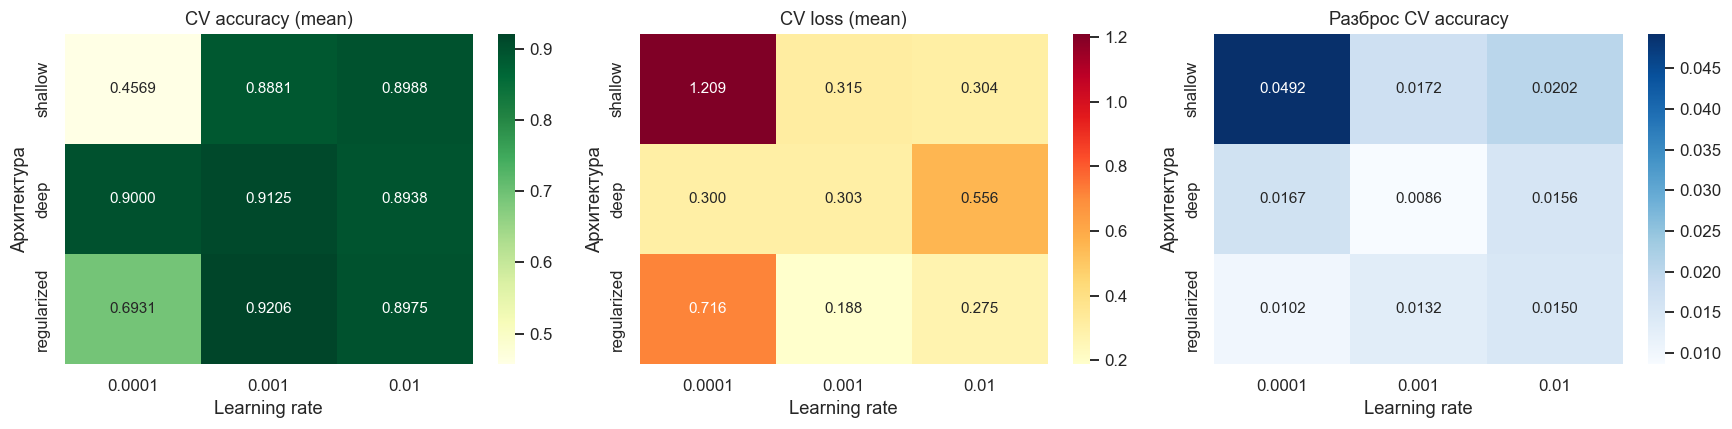

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, value, title, fmt, cmap in [
    (axes[0], "mean_accuracy", "CV accuracy (mean)", ".4f", "YlGn"),
    (axes[1], "mean_loss", "CV loss (mean)", ".3f", "YlOrRd"),
    (axes[2], "std_accuracy", "Разброс CV accuracy", ".4f", "Blues")]:
    table = cv_table.pivot(index="architecture", columns="learning_rate", values=value).reindex(ARCHITECTURES)
    sns.heatmap(table, annot=True, fmt=fmt, cmap=cmap, ax=ax)
    ax.set(title=title, xlabel="Learning rate", ylabel="Архитектура")
show("cv_heatmaps")
lr_means = cv_table.groupby("learning_rate").mean_accuracy.mean()
arch_means = cv_table.groupby("architecture").mean_accuracy.mean()
lr_effect = float(lr_means.max()-lr_means.min())
arch_effect = float(arch_means.max()-arch_means.min())
stronger = "learning rate" if lr_effect > arch_effect else "архитектура"
ANALYSIS["heatmaps"] = (
    "Средняя accuracy по трём архитектурам при каждом lr: "
    + "; ".join(f"{lr:g} → {v:.4f}" for lr,v in lr_means.items()) + ". "
    "Средняя accuracy по трём lr для каждой архитектуры: "
    + "; ".join(f"{a} → {v:.4f}" for a,v in arch_means.items()) + ". "
    f"Размах маргинальных средних: lr={100*lr_effect:.2f} п.п., "
    f"архитектура={100*arch_effect:.2f} п.п.; больший размах даёт {stronger}. "
    "Это описательная чувствительность в заданной сетке и при бюджете 60 эпох, "
    "а не причинная оценка или универсальный рейтинг важности параметров. "
    "Взаимодействия архитектуры и шага видны по отдельным ячейкам; "
    "BatchNormalization и Dropout здесь исследуются как единая архитектурная конфигурация.")

### Интерпретация результатов

Средняя accuracy по трём архитектурам при каждом lr: 0.0001 → 0.6833; 0.001 → 0.9071; 0.01 → 0.8967. Средняя accuracy по трём lr для каждой архитектуры: deep → 0.9021; regularized → 0.8371; shallow → 0.7479. Размах маргинальных средних: lr=22.38 п.п., архитектура=15.42 п.п.; больший размах даёт learning rate. Это описательная чувствительность в заданной сетке и при бюджете 60 эпох, а не причинная оценка или универсальный рейтинг важности параметров. Взаимодействия архитектуры и шага видны по отдельным ячейкам; BatchNormalization и Dropout здесь исследуются как единая архитектурная конфигурация.

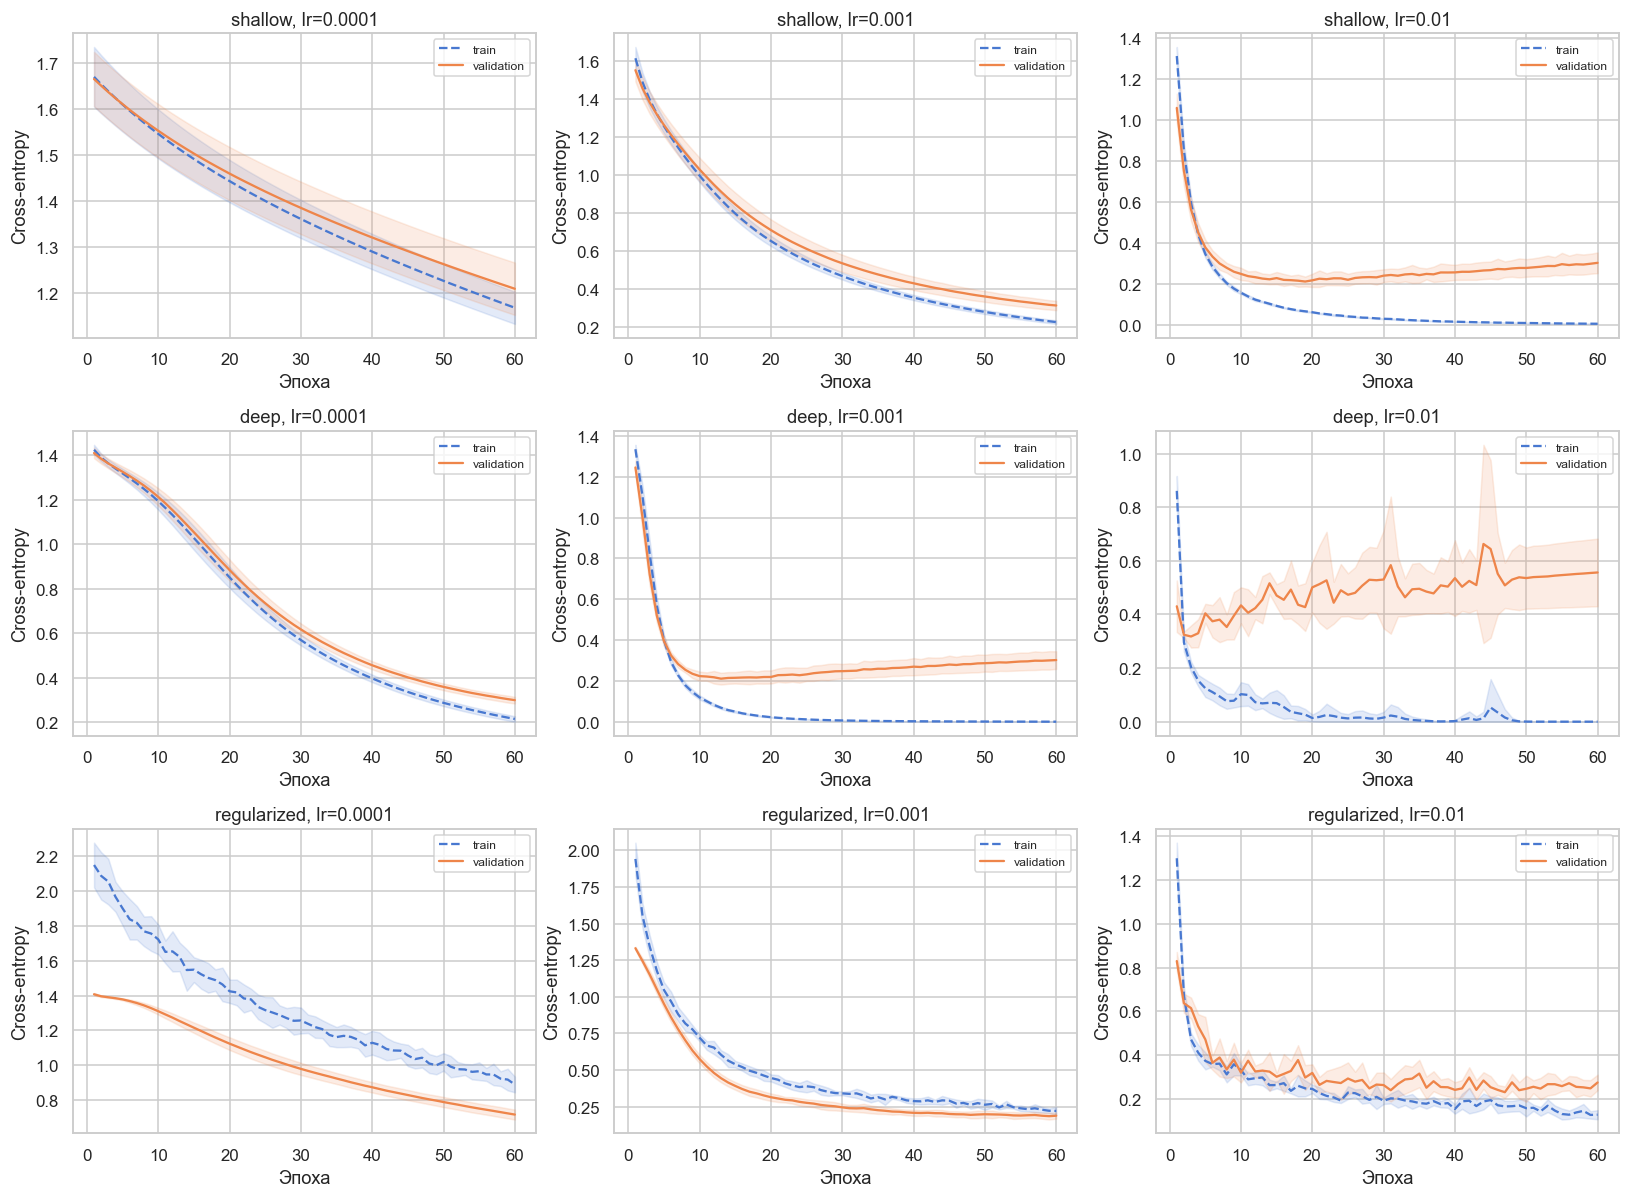

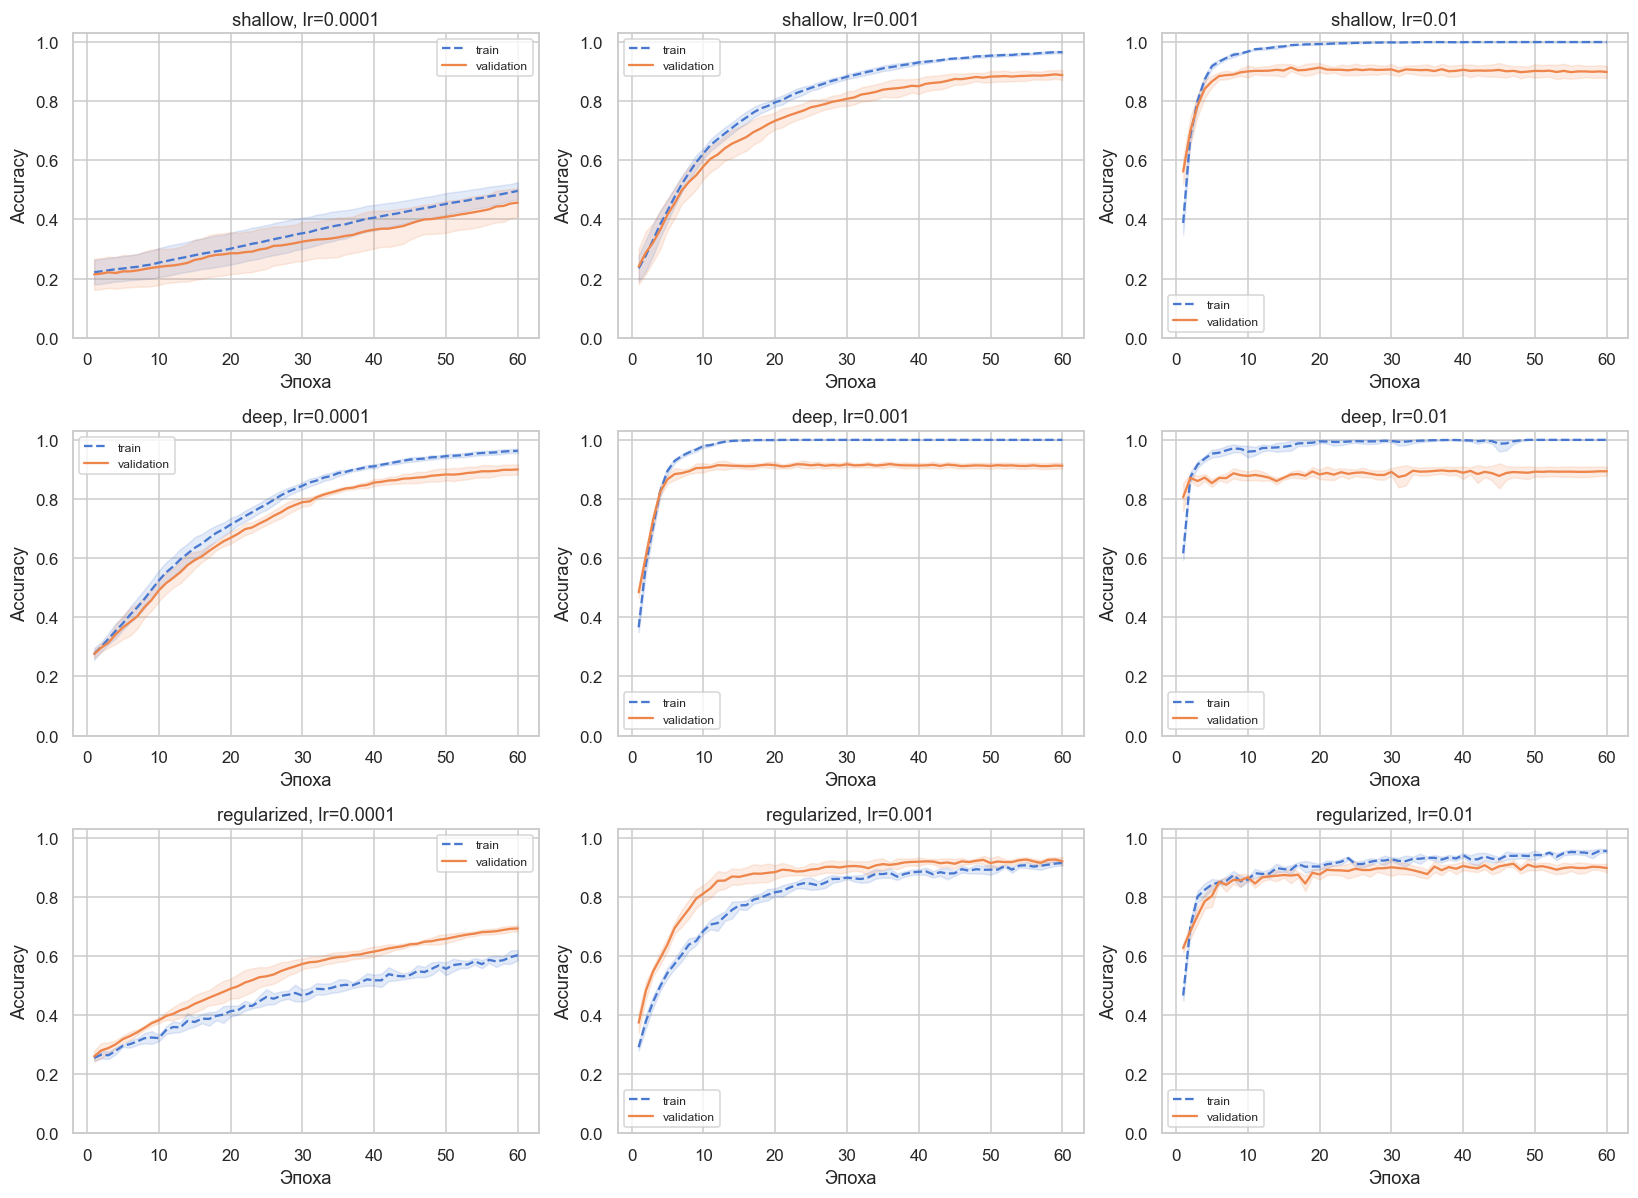

,min_mean_val_loss_epoch,min_mean_val_loss,last_mean_val_loss,last_mean_train_loss,late_train_loss_change,late_val_loss_change
config,,,,,,
shallow_lr_0.0001,60,1.20931,1.20931,1.16799,-0.02920,-0.02670
shallow_lr_0.001,60,0.31524,0.31524,0.22795,-0.02628,-0.02309
shallow_lr_0.01,19,0.21255,0.30395,0.00644,-0.00181,0.00958
deep_lr_0.0001,60,0.30003,0.30003,0.21542,-0.03550,-0.02890
deep_lr_0.001,13,0.21151,0.30257,0.00112,-0.00032,0.00782
deep_lr_0.01,3,0.31769,0.55646,0.00007,-0.00005,0.01011
regularized_lr_0.0001,60,0.71649,0.71649,0.88929,-0.04961,-0.03532
regularized_lr_0.001,59,0.18471,0.18755,0.22063,-0.02390,-0.00425
regularized_lr_0.01,47,0.23028,0.27468,0.12742,-0.01668,0.00145


In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, architecture in enumerate(ARCHITECTURES):
    for c, lr in enumerate(LEARNING_RATES):
        cfg = config_id(architecture, lr)
        h = [HISTORIES[f"{cfg}/fold_{fold}"] for fold in range(1, 6)]
        ax = axes[r, c]
        epochs = np.arange(1, EPOCHS+1)
        for metric, label, style in [("loss", "train", "--"), ("val_loss", "validation", "-")]:
            values = np.asarray([run[metric] for run in h])
            mean, std = values.mean(axis=0), values.std(axis=0)
            line, = ax.plot(epochs, mean, style, label=label)
            ax.fill_between(epochs, np.maximum(mean-std, 0), mean+std, alpha=0.15, color=line.get_color())
        ax.set(title=f"{architecture}, lr={lr:g}", xlabel="Эпоха", ylabel="Cross-entropy")
        ax.legend(fontsize=8)
show("all_loss_curves")

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
curve_diagnostics = []
for r, architecture in enumerate(ARCHITECTURES):
    for c, lr in enumerate(LEARNING_RATES):
        cfg = config_id(architecture, lr)
        h = [HISTORIES[f"{cfg}/fold_{fold}"] for fold in range(1, 6)]
        ax = axes[r, c]
        for metric, label, style in [("accuracy", "train", "--"), ("val_accuracy", "validation", "-")]:
            values = np.asarray([run[metric] for run in h])
            mean, std = values.mean(axis=0), values.std(axis=0)
            line, = ax.plot(np.arange(1, EPOCHS+1), mean, style, label=label)
            ax.fill_between(np.arange(1, EPOCHS+1), np.clip(mean-std,0,1),
                            np.clip(mean+std,0,1), alpha=0.15, color=line.get_color())
        ax.set(title=f"{architecture}, lr={lr:g}", xlabel="Эпоха", ylabel="Accuracy", ylim=(0,1.03))
        ax.legend(fontsize=8)
        losses = np.asarray([run["val_loss"] for run in h]).mean(axis=0)
        train_losses = np.asarray([run["loss"] for run in h]).mean(axis=0)
        curve_diagnostics.append({"config": cfg, "min_mean_val_loss_epoch": int(losses.argmin())+1,
            "min_mean_val_loss": float(losses.min()), "last_mean_val_loss": float(losses[-1]),
            "last_mean_train_loss": float(train_losses[-1]),
            "late_train_loss_change": float(train_losses[-5:].mean()-train_losses[-10:-5].mean()),
            "late_val_loss_change": float(losses[-5:].mean()-losses[-10:-5].mean())})
show("all_accuracy_curves")
diagnostics = pd.DataFrame(curve_diagnostics).set_index("config")
display(diagnostics.round(5))
diagnostics.to_csv(ARTIFACTS / "curve_diagnostics.csv")
deep_high = diagnostics.loc["deep_lr_0.01"]
selected_curve = diagnostics.loc[best_config]
ANALYSIS["curves"] = (
    "Каждая панель показывает среднее и ±1 std пяти фолдов; каждый из 45 запусков "
    "также доступен отдельно в TensorBoard. Для deep, lr=0.01 минимум среднего "
    f"validation loss={deep_high.min_mean_val_loss:.4f} на эпохе "
    f"{int(deep_high.min_mean_val_loss_epoch)}, последнее значение={deep_high.last_mean_val_loss:.4f}, "
    f"train loss={deep_high.last_mean_train_loss:.4f}. "
    f"Для выбранной конфигурации минимум среднего val_loss на эпохе "
    f"{int(selected_curve.min_mean_val_loss_epoch)}, конечный train/validation loss="
    f"{selected_curve.last_mean_train_loss:.4f}/{selected_curve.last_mean_val_loss:.4f}. "
    "Минимумы приведены только как диагностика: веса этих эпох не выбирались. "
    "Рост validation loss при продолжающемся снижении train loss указывает на "
    "переобучение; одновременное высокое значение обеих ошибок и продолжающееся "
    "снижение совместимы с недообучением. У Dropout/BatchNorm train и validation "
    "рассчитываются в разных режимах, поэтому отрицательный разрыв возможен.")

### Интерпретация результатов

Каждая панель показывает среднее и ±1 std пяти фолдов; каждый из 45 запусков также доступен отдельно в TensorBoard. Для deep, lr=0.01 минимум среднего validation loss=0.3177 на эпохе 3, последнее значение=0.5565, train loss=0.0001. Для выбранной конфигурации минимум среднего val_loss на эпохе 59, конечный train/validation loss=0.2206/0.1875. Минимумы приведены только как диагностика: веса этих эпох не выбирались. Рост validation loss при продолжающемся снижении train loss указывает на переобучение; одновременное высокое значение обеих ошибок и продолжающееся снижение совместимы с недообучением. У Dropout/BatchNorm train и validation рассчитываются в разных режимах, поэтому отрицательный разрыв возможен.

**Диагностика по измеренным историям.**

У shallow_lr_0.0001 есть признаки недообучения при заданном бюджете: финальные train/validation accuracy=0.4967/0.4569, а средний val_loss последних пяти эпох ещё снизился относительно предыдущих пяти на 0.0267.

У shallow_lr_0.01 есть признаки переобучения: после минимума среднего val_loss на эпохе 19 он вырос с 0.2126 до 0.3039, тогда как train loss снизился с 0.0672 до 0.0064.

У deep_lr_0.001 есть признаки переобучения: после минимума среднего val_loss на эпохе 13 он вырос с 0.2115 до 0.3026, тогда как train loss снизился с 0.0693 до 0.0011.

У deep_lr_0.01 есть признаки переобучения: после минимума среднего val_loss на эпохе 3 он вырос с 0.3177 до 0.5565, тогда как train loss снизился с 0.2037 до 0.0001.

У regularized_lr_0.0001 есть признаки недообучения при заданном бюджете: финальные train/validation accuracy=0.6030/0.6931, а средний val_loss последних пяти эпох ещё снизился относительно предыдущих пяти на 0.0353.

У regularized_lr_0.01 есть признаки переобучения: после минимума среднего val_loss на эпохе 47 он вырос с 0.2303 до 0.2747, тогда как train loss снизился с 0.1652 до 0.1274.

Диагностические пороги заданы явно: рост val_loss более 0.02 при снижении train loss после его validation-минимума; для недообучения — обе accuracy ниже 0.85 и снижение среднего val_loss ещё более 0.01 за последние два окна по пять эпох. Эти признаки служат интерпретации кривых и не меняют выбор конфигурации или эпох.

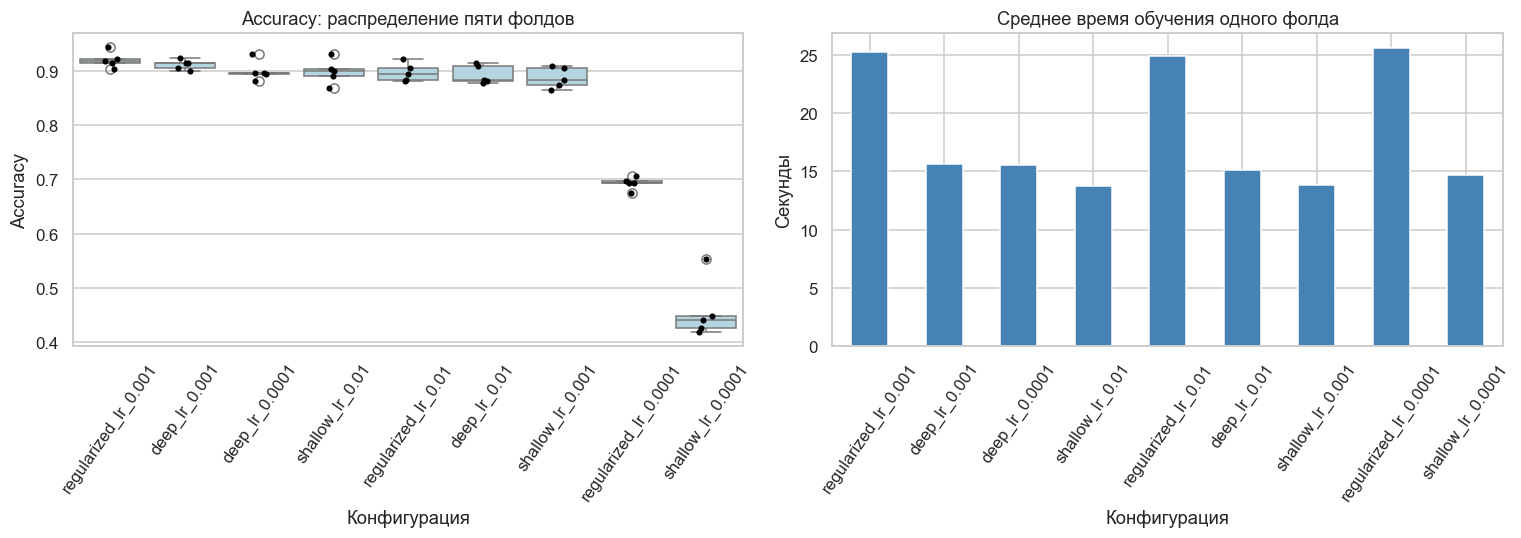

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = cv_table.config.tolist()
sns.boxplot(data=fold_metrics, x="config", y="accuracy", order=order, color="lightblue", ax=axes[0])
sns.stripplot(data=fold_metrics, x="config", y="accuracy", order=order, color="black", size=4, ax=axes[0])
axes[0].set(title="Accuracy: распределение пяти фолдов", xlabel="Конфигурация", ylabel="Accuracy")
cv_table.set_index("config").mean_training_seconds.plot.bar(ax=axes[1], color="steelblue")
axes[1].set(title="Среднее время обучения одного фолда", xlabel="Конфигурация", ylabel="Секунды")
for ax in axes:
    ax.tick_params(axis="x", rotation=55)
show("stability_and_time")
best_folds = fold_metrics[fold_metrics.config == best_config]
most_stable = cv_table.loc[cv_table.std_accuracy.idxmin()]
fastest = cv_table.loc[cv_table.mean_training_seconds.idxmin()]
ANALYSIS["stability"] = (
    f"Выбранная {best_config}: accuracy по фолдам "
    f"{best_folds.sort_values('fold').accuracy.round(4).tolist()}, "
    f"диапазон {best_folds.accuracy.min():.4f}–{best_folds.accuracy.max():.4f}. "
    f"Минимальный std accuracy у {most_stable.config}: {most_stable.std_accuracy:.4f}; "
    f"наименьшее среднее время у {fastest.config}: {fastest.mean_training_seconds:.2f} с. "
    "Малый разброс при низкой средней accuracy может означать устойчивое недообучение. "
    "Выбор следует первичному критерию средней accuracy, а loss, std и время объясняют "
    "компромиссы между качеством и затратами. Замеры включают TensorBoard histogram_freq=1 "
    "и относятся к этой машине; они не являются универсальным бенчмарком архитектур.")

### Интерпретация результатов

Выбранная regularized_lr_0.001: accuracy по фолдам [0.9438, 0.9219, 0.9031, 0.9156, 0.9188], диапазон 0.9031–0.9437. Минимальный std accuracy у deep_lr_0.001: 0.0086; наименьшее среднее время у shallow_lr_0.01: 13.73 с. Малый разброс при низкой средней accuracy может означать устойчивое недообучение. Выбор следует первичному критерию средней accuracy, а loss, std и время объясняют компромиссы между качеством и затратами. Замеры включают TensorBoard histogram_freq=1 и относятся к этой машине; они не являются универсальным бенчмарком архитектур.

In [12]:
original_cwd = Path.cwd()
try:
    # ASCII working directory avoids TensorFlow's Unicode Windows path issue.
    os.chdir(TB_WORKDIR)
    get_ipython().run_line_magic("load_ext", "tensorboard")  # %load_ext tensorboard
    get_ipython().run_line_magic("tensorboard", f"--logdir logs/additional/{RUN_ID} --port 6007")
except Exception as exc:
    print("Встраивание TensorBoard недоступно:", type(exc).__name__)
    print("Используйте: python view_tensorboard.py --additional")
finally:
    os.chdir(original_cwd)
print("Снимок логов:", (ARTIFACTS / "tensorboard").as_posix())
ANALYSIS["tensorboard"] = (
    "Сохранены 45 пар train/validation-журналов для CV и один train-журнал refit. "
    "TensorBoard пишет epoch_accuracy, epoch_loss и гистограммы весов на каждой эпохе. "
    "Run names содержат архитектуру, learning rate и номер фолда; refit выделен отдельно. "
    "Вызваны %load_ext tensorboard и %tensorboard с портом 6007. "
    "Все события скопированы в additional/artifacts/tensorboard, поэтому доступны "
    "после клонирования ветки. При кириллице в пути Windows запись и встраивание "
    "используют временный ASCII-каталог. Статические сетки loss и accuracy "
    "сохранены в самом ноутбуке и PNG независимо от доступности виджета.")

ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

Снимок логов: additional/artifacts/tensorboard


### Интерпретация результатов

Сохранены 45 пар train/validation-журналов для CV и один train-журнал refit. TensorBoard пишет epoch_accuracy, epoch_loss и гистограммы весов на каждой эпохе. Run names содержат архитектуру, learning rate и номер фолда; refit выделен отдельно. Вызваны %load_ext tensorboard и %tensorboard с портом 6007. Все события скопированы в additional/artifacts/tensorboard, поэтому доступны после клонирования ветки. При кириллице в пути Windows запись и встраивание используют временный ASCII-каталог. Статические сетки loss и accuracy сохранены в самом ноутбуке и PNG независимо от доступности виджета.

## 6. Финальная оценка и сравнение с baseline

,accuracy,loss,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,training_seconds
LogisticRegression,0.9650,0.18915,0.96504,0.9650,0.96499,0.99867,0.04783
regularized_lr_0.001,0.9425,0.14715,0.94324,0.9425,0.94211,0.99628,21.19043


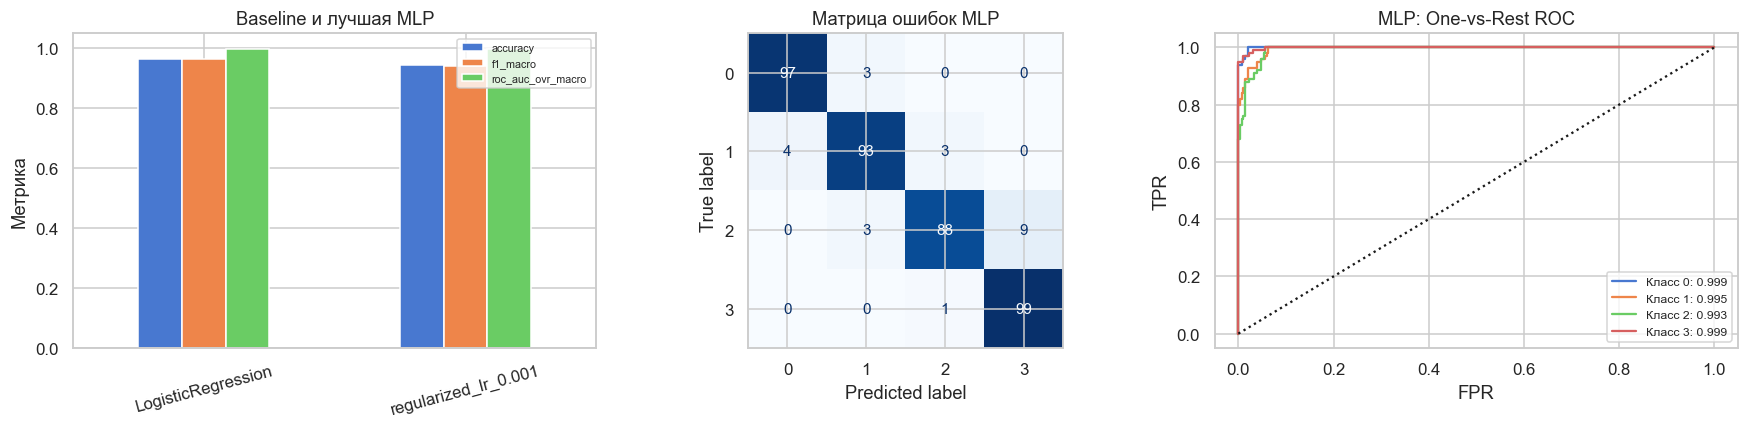

In [13]:
final_model = search.best_estimator_
final_proba = final_model.predict_proba(X_test)
final_pred = final_model.predict(X_test)
final_metrics = metric_row(y_test, final_pred, final_proba)
final_table = pd.DataFrame([baseline_metrics, final_metrics], index=["LogisticRegression", best_config])
final_table["training_seconds"] = [baseline_seconds, final_model.training_seconds_]
display(final_table.round(5))
final_table.to_csv(ARTIFACTS / "final_metrics.csv", index_label="model")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
final_table[["accuracy", "f1_macro", "roc_auc_ovr_macro"]].plot.bar(ax=axes[0], rot=15)
axes[0].set(title="Baseline и лучшая MLP", ylabel="Метрика", ylim=(0,1.05))
axes[0].legend(fontsize=7)
ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred, labels=CLASSES),
    display_labels=CLASSES).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Матрица ошибок MLP")
y_test_bin = label_binarize(y_test, classes=CLASSES)
for c in CLASSES:
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], final_proba[:, c])
    axes[2].plot(fpr, tpr, label=f"Класс {c}: {auc(fpr,tpr):.3f}")
axes[2].plot([0,1],[0,1],"k:")
axes[2].set(title="MLP: One-vs-Rest ROC", xlabel="FPR", ylabel="TPR")
axes[2].legend(fontsize=8)
show("final_comparison")
final_model.model_.save(ARTIFACTS / "best_model.keras")
joblib.dump({"preprocessor": final_model.preprocessor_, "features": FEATURES,
             "classes": CLASSES}, ARTIFACTS / "neural_preprocessing.joblib")
pd.DataFrame({"row_index": X_test.index, "truth": y_test.to_numpy(),
    "baseline_prediction": baseline_pred, "neural_prediction": final_pred,
    **{f"baseline_p{c}": baseline_proba[:, c] for c in CLASSES},
    **{f"neural_p{c}": final_proba[:, c] for c in CLASSES}}).to_csv(
        ARTIFACTS / "test_predictions.csv", index=False)
delta = final_metrics["accuracy"]-baseline_metrics["accuracy"]
ANALYSIS["final"] = (
    f"GridSearchCV обучил выбранную {best_config} с нуля на всех 1600 train-объектах "
    f"в течение {EPOCHS} эпох. Baseline Accuracy={baseline_metrics['accuracy']:.4f}, "
    f"MLP Accuracy={final_metrics['accuracy']:.4f}; изменение {100*delta:+.2f} п.п. "
    f"({100*delta/baseline_metrics['accuracy']:+.2f}% относительно baseline). "
    f"Loss: {baseline_metrics['loss']:.4f} → {final_metrics['loss']:.4f}; "
    f"F1-macro MLP={final_metrics['f1_macro']:.4f}, ROC-AUC={final_metrics['roc_auc_ovr_macro']:.4f}. "
    f"Ошибок MLP: {int((final_pred != y_test).sum())}/400; "
    f"refit занял {final_model.training_seconds_:.2f} с. "
    "Baseline и победитель используют один и тот же тест. Отрицательная дельта "
    "сохраняется как результат: настройка MLP не обязана превосходить сильную линейную модель.")

### Интерпретация результатов

GridSearchCV обучил выбранную regularized_lr_0.001 с нуля на всех 1600 train-объектах в течение 60 эпох. Baseline Accuracy=0.9650, MLP Accuracy=0.9425; изменение -2.25 п.п. (-2.33% относительно baseline). Loss: 0.1892 → 0.1472; F1-macro MLP=0.9421, ROC-AUC=0.9963. Ошибок MLP: 23/400; refit занял 21.19 с. Baseline и победитель используют один и тот же тест. Отрицательная дельта сохраняется как результат: настройка MLP не обязана превосходить сильную линейную модель.

In [14]:
reference_config = "shallow_lr_0.001"
reference_row = cv_table.set_index("config").loc[reference_config]
cv_delta = float(winner.mean_accuracy-reference_row.mean_accuracy)
summary = pd.DataFrame({"Значение": [9, 45, EPOCHS, winner.mean_accuracy,
    winner.std_accuracy, baseline_metrics["accuracy"], final_metrics["accuracy"], 100*delta]},
    index=["Конфигураций", "CV-обучений", "Эпох в каждом запуске", "Лучшая CV accuracy",
           "Std CV accuracy", "Baseline test accuracy", "MLP test accuracy", "Изменение, п.п."])
display(summary)
winning_gap = float(winner.mean_train_accuracy-winner.mean_accuracy)
ANALYSIS["conclusion"] = (
    f"Точка отсчёта внутри нейросетевой сетки {reference_config}: "
    f"CV Accuracy={reference_row.mean_accuracy:.4f}; выбранная {best_config}: "
    f"{winner.mean_accuracy:.4f}; изменение {100*cv_delta:+.2f} п.п. "
    f"На тесте изменение относительно LogisticRegression равно {100*delta:+.2f} п.п. "
    "Эти сравнения отвечают разным вопросам: первое описывает настройку MLP на общих "
    "фолдах, второе — конкуренцию финальной сети с линейным baseline. "
    f"Для победителя средние inference train/validation accuracy="
    f"{winner.mean_train_accuracy:.4f}/{winner.mean_accuracy:.4f}, разрыв "
    f"{100*winning_gap:.2f} п.п. Описательная чувствительность к lr: "
    f"{100*lr_effect:.2f} п.п., к архитектуре: {100*arch_effect:.2f} п.п. "
    "Высокий train-score при росте val_loss указывает на переобучение; медленная "
    "сходимость при малом lr зависит от фиксированного бюджета 60 эпох. "
    "Средние CV-оценки победителя могут быть оптимистичны вследствие выбора среди "
    "9 кандидатов. Фолды пересекаются обучающими частями, их std не является "
    "доверительным интервалом. Единственный тест из 400 объектов и его использование "
    "в основной лабораторной ограничивают обобщение выводов; одна ошибка меняет "
    "Accuracy на 0.25 п.п. Для независимой последующей оценки нужны новые данные "
    "или заранее спланированная повторная вложенная CV.")
report = {"versions": versions, "random_state": RANDOM_STATE, "epochs": EPOCHS,
    "batch_size": BATCH_SIZE, "dataset_sha256": dataset_sha256, "n_configs": 9,
    "n_cv_fits": 45, "n_total_neural_fits": 46, "best_config": best_config,
    "best_params": search.best_params_, "best_cv_accuracy": float(winner.mean_accuracy),
    "best_cv_std_accuracy": float(winner.std_accuracy), "best_cv_loss": float(winner.mean_loss),
    "baseline_test": baseline_metrics, "neural_test": final_metrics,
    "test_accuracy_delta_pp": 100*delta, "cv_accuracy_delta_vs_shallow_pp": 100*cv_delta,
    "lr_marginal_range_pp": 100*lr_effect, "architecture_marginal_range_pp": 100*arch_effect,
    "baseline_training_seconds": baseline_seconds, "refit_training_seconds": final_model.training_seconds_,
    "total_search_seconds": search_seconds, "selection": "mean_accuracy desc, mean_loss asc, std_accuracy asc, stable order",
    "fold_seeds": [RANDOM_STATE+i for i in range(1,6)], "refit_seed": RANDOM_STATE,
    "reused_lab2_holdout": True}
dump_json(ARTIFACTS / "experiment_report.json", report)
dump_json(ARTIFACTS / "analyses.json", ANALYSIS)
assert len(HISTORIES) == 46 and all(len(h["loss"]) == EPOCHS for h in HISTORIES.values())
display({"application/vnd.lab2.additional-analysis+json": ANALYSIS}, raw=True)

,Значение
Конфигураций,9.000000
CV-обучений,45.000000
Эпох в каждом запуске,60.000000
Лучшая CV accuracy,0.920625
Std CV accuracy,0.013199
Baseline test accuracy,0.965000
MLP test accuracy,0.942500
"Изменение, п.п.",-2.250000


### Интерпретация результатов

Точка отсчёта внутри нейросетевой сетки shallow_lr_0.001: CV Accuracy=0.8881; выбранная regularized_lr_0.001: 0.9206; изменение +3.25 п.п. На тесте изменение относительно LogisticRegression равно -2.25 п.п. Эти сравнения отвечают разным вопросам: первое описывает настройку MLP на общих фолдах, второе — конкуренцию финальной сети с линейным baseline. Для победителя средние inference train/validation accuracy=0.9920/0.9206, разрыв 7.14 п.п. Описательная чувствительность к lr: 22.38 п.п., к архитектуре: 15.42 п.п. Высокий train-score при росте val_loss указывает на переобучение; медленная сходимость при малом lr зависит от фиксированного бюджета 60 эпох. Средние CV-оценки победителя могут быть оптимистичны вследствие выбора среди 9 кандидатов. Фолды пересекаются обучающими частями, их std не является доверительным интервалом. Единственный тест из 400 объектов и его использование в основной лабораторной ограничивают обобщение выводов; одна ошибка меняет Accuracy на 0.25 п.п. Для независимой последующей оценки нужны новые данные или заранее спланированная повторная вложенная CV.

**Фактический итог сравнения.** Настроенная MLP не повысила тестовую accuracy относительно фиксированной LogisticRegression: изменение -2.25 п.п. Эффект настройки внутри нейросетевой сетки относительно shallow/lr=0.001 составляет +3.25 п.п. средней CV accuracy. Оба результата сохранены без предположения о преимуществе MLP.

### Воспроизведение и источники

- [Исходный набор](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification).
- [GridSearchCV: многокритериальное оценивание и callable refit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [Контракт sklearn-совместимого estimator](https://scikit-learn.org/stable/developers/develop.html).
- [TensorBoard callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/TensorBoard).

Установка зависимостей: `python -m pip install -r requirements-lock.txt`.
Полный расчёт: `python generate_additional_notebook.py`.
Проверка сохранённых результатов: `python validate_additional_notebook.py`.
Мониторинг: `python view_tensorboard.py --additional` (порт 6007).
Артефакты дополнительного задания находятся в `additional/artifacts/`.
Результаты основной лабораторной хранятся отдельно в прежних файлах.